# 🫁 Pediatric Chest X-Ray 3-Class Pneumonia Diagnosis Pipeline
### Transfer Learning (MobileNetV2) & Explainable AI (Grad-CAM)

**Author:** Loay Alrazi  
**Domain:** Medical Imaging / Computer Vision  
**Task:** Multiclass Classification: `BACTERIAL PNEUMONIA` vs. `NORMAL` vs. `VIRAL PNEUMONIA`  

---

## Overview & Clinical Motivation
Pneumonia remains a leading cause of pediatric morbidity worldwide. Differentiating between **bacterial** and **viral** pneumonia on chest radiographs is clinically critical: bacterial infections require prompt antibiotic administration, whereas viral cases demand supportive care and antibiotic avoidance to prevent antimicrobial resistance.

This notebook establishes an end-to-end deep learning pipeline:
1. **Dataset Structuring:** 3-way split separating bacterial and viral subclasses.
2. **Transfer Learning:** Fine-tuning a pre-trained `MobileNetV2` backbone.
3. **Rigorous Evaluation:** Per-class sensitivity, specificity, and confusion matrix.
4. **Visual Interpretability:** Anatomical localization of pathology using **Grad-CAM**.

## 1. Dataset Preparation & 3-Class Hierarchy
Prepares the directory structure to isolate `BACTERIAL` and `VIRAL` cases from raw pneumonia tags.

In [1]:
from prepare_three_classes import prepare_dataset
prepared_path = prepare_dataset()

Three-class dataset ready. Original images and splits are unchanged.
Split     BACTERIAL  NORMAL  VIRAL  Total
train          1771    1071    992   3834
val             404     270    251    925
test            242     234    148    624


## 2. Reproducible Environment & Hyperparameter Configuration
Configures fixed seeds, compute device (CUDA / CPU), and batch dimensions.

In [2]:
from pathlib import Path
import copy
import random
import time
import sys
from tqdm import tqdm
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score
from helpers import show_batch, plot_history, plot_confusion, show_prediction, show_gradcam

# نثبت البداية قدر الإمكان لتسهيل مقارنة التجارب.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

# نضع الإعدادات التي سنغيّرها أثناء التجربة في مكان واحد.
IMAGE_SIZE, BATCH_SIZE, EPOCHS = 224, 32, 3
LEARNING_RATE = 0.001
TRAIN_NOW = True
# النموذج والبيانات يجب أن يكونا على Device نفسها.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Configure input directory for the 3-class cohort.
DATA_DIR = Path("data/chest_xray_3class")
assert DATA_DIR.is_dir(), "Dataset directory not found."
# نستخدم Initial Weights المرفقة لتجنب التحميل أثناء الدرس.
torch.hub.set_dir("artifacts/torch")
print("Device:", device)
print("PyTorch:", torch.__version__)

Device: cuda
PyTorch: 2.6.0+cu124


## 3. Data Augmentation & Normalization Pipeline
Applies standard ImageNet channel moments $(\mu, \sigma)$ and spatial transformations.

In [3]:
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
# نطبق العمليات بالترتيب نفسه على كل صورة.
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# أسماء المجلدات تحدد Classes، وTransform تجهز الصورة عند قراءتها.
train_data = datasets.ImageFolder(DATA_DIR / "train", transform=transform)
val_data = datasets.ImageFolder(DATA_DIR / "val", transform=transform)
test_data = datasets.ImageFolder(DATA_DIR / "test", transform=transform)
class_names = train_data.classes
# نتحقق أن معنى الأرقام متطابق في Train وValidation وTest.
assert class_names == ["BACTERIAL", "NORMAL", "VIRAL"]
assert train_data.class_to_idx == val_data.class_to_idx == test_data.class_to_idx

print("Class mapping:", train_data.class_to_idx)
for name, dataset in [("Train", train_data), ("Validation", val_data), ("Test", test_data)]:
    counts = np.bincount(dataset.targets, minlength=len(class_names))
    print(name, len(dataset), dict(zip(class_names, counts.tolist())))

Class mapping: {'BACTERIAL': 0, 'NORMAL': 1, 'VIRAL': 2}
Train 3834 {'BACTERIAL': 1771, 'NORMAL': 1071, 'VIRAL': 992}
Validation 925 {'BACTERIAL': 404, 'NORMAL': 270, 'VIRAL': 251}
Test 624 {'BACTERIAL': 242, 'NORMAL': 234, 'VIRAL': 148}


## 4. Batched Data Loading
Instantiates PyTorch DataLoaders for the `train`, `val`, and `test` cohorts.

Images: (32, 3, 224, 224) torch.float32
Labels: (32,) torch.int64


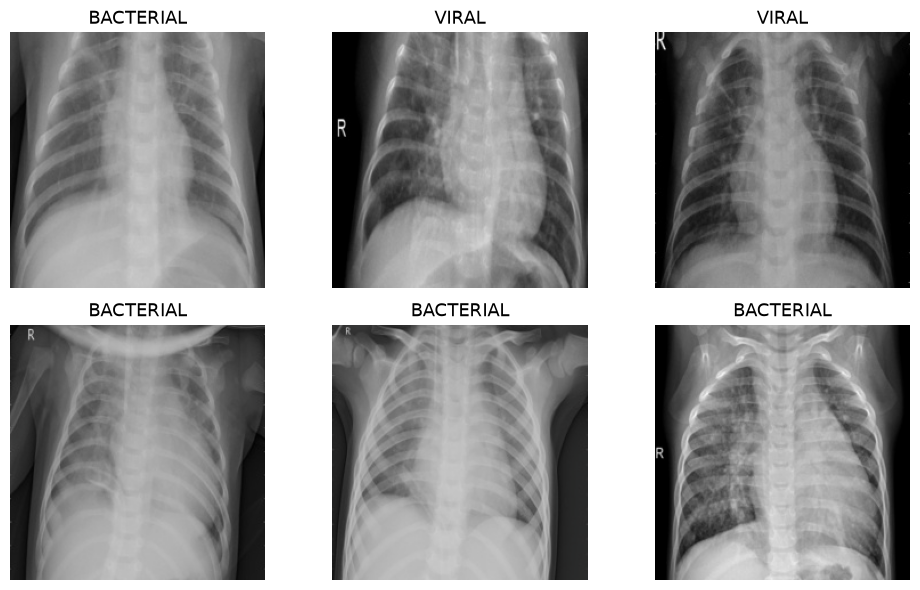

In [4]:
# نجمع الصور في Batches ونخلط Train فقط.
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# نأخذ Batch واحدة لنرى ما يدخل إلى النموذج.
images, labels = next(iter(train_loader))
print("Images:", tuple(images.shape), images.dtype)
print("Labels:", tuple(labels.shape), labels.dtype)
show_batch(images, labels, class_names, MEAN, STD)

## 5. MobileNetV2 Transfer Learning Architecture
Initializes pre-trained MobileNetV2 backbone, freezes feature representations, and configures a 3-class linear projection head.

In [5]:
# نبدأ من Weights تعلمت Features عامة على ImageNet.
model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V2)

# نثبت Backbone وندرّب Classifier الجديدة فقط.
for parameter in model.features.parameters():
    parameter.requires_grad = False
# آخر Layer تخرج درجة لكل Class في مشروعنا.
# Replace classification head with 3-class linear projection.
model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, len(class_names))
model = model.to(device)
# هذه Loss تستقبل Logits مباشرة، لذلك لا نضيف Softmax هنا.
loss_fn = nn.CrossEntropyLoss()
# نعطي Optimizer Parameters الخاصة بـClassifier فقط.
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=LEARNING_RATE)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Classifier:", model.classifier)
print("Trainable parameters:", trainable)

Classifier: Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=3, bias=True)
)
Trainable parameters: 3843


## 6. Optimization Strategy & Training Loop Definition
Defines epoch execution with Cross-Entropy loss and accuracy tracking.

In [6]:
def run_epoch(loader, training):
    # نفعّل Training behavior أو Evaluation behavior حسب المرحلة.
    model.train(training)
    # نبقي Backbone ثابتة، بما فيها إحصاءات BatchNorm.
    model.features.eval()
    total_loss, total_correct, total = 0.0, 0, 0
    phase = "Training" if training else "Validation"

    # يظهر Progress Bar قبل قراءة أول Batch، ويتحدث بعد اكتمالها.
    with tqdm(total=len(loader), desc=phase, unit="batch",
              file=sys.stdout, dynamic_ncols=True, mininterval=0.5) as progress:
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if training:
                # نبدأ Batch جديدة بدون Gradients متراكمة من السابقة.
                optimizer.zero_grad(set_to_none=True)
            with torch.set_grad_enabled(training):
                # Forward Pass ثم قياس الخطأ مقارنةً بـLabels الصحيحة.
                logits = model(x)
                loss = loss_fn(logits, y)
                if training:
                    # نحسب Gradients أولًا، ثم نحدّث Weights.
                    loss.backward()
                    optimizer.step()
            # نزن Loss بعدد الصور؛ آخر Batch قد تكون أصغر.
            total_loss += loss.item() * len(y)
            # == تقارن Prediction بـLabel؛ نجمع عدد الإجابات الصحيحة.
            total_correct += (logits.argmax(dim=1) == y).sum().item()
            total += len(y)

            # المتوسط محسوب على الصور التي اكتملت حتى الآن.
            progress.set_postfix(Loss=f"{total_loss / total:.4f}",
                                 Accuracy=f"{total_correct / total:.1%}", refresh=False)
            progress.update(1)
    return total_loss / total, total_correct / total

## 7. Model Training & Validation Execution
Executes fine-tuning across specified epochs or loads serialized weights.

In [7]:
run_source = None
print(f"Training pipeline initialized | TRAIN_NOW={TRAIN_NOW} | Device={device}", flush=True)
if TRAIN_NOW:
    if not isinstance(EPOCHS, int) or EPOCHS < 1:
        raise ValueError("EPOCHS must be a positive integer.")
    print(f"Starting training: {EPOCHS} epoch(s) | "
          f"Train: {len(train_loader)} batches | Validation: {len(val_loader)} batches",
          flush=True)
    history = []
    best_loss, best_epoch, best_state = float("inf"), 0, None
    started = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        print(f"\nEpoch {epoch}/{EPOCHS}", flush=True)
        train_loss, train_acc = run_epoch(train_loader, training=True)
        val_loss, val_acc = run_epoch(val_loader, training=False)
        history.append([train_loss, val_loss, train_acc, val_acc])
        print(f"Epoch {epoch}: Train loss={train_loss:.3f}, acc={train_acc:.1%} | "
              f"Val loss={val_loss:.3f}, acc={val_acc:.1%}", flush=True)
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch
            # نسخة مستقلة من أفضل Weights حتى الآن.
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    training_seconds = time.perf_counter() - started
    run_source = "trained_here"
    print(f"Training complete. Selected epoch: {best_epoch}; "
          f"training time: {training_seconds:.1f} seconds", flush=True)
else:
    checkpoint_path = Path("artifacts/pneumonia_3class.pt")
    if not checkpoint_path.is_file():
        raise FileNotFoundError("Checkpoint not found. Set TRAIN_NOW=True to train.")
    print("Loading your three-class checkpoint...", flush=True)
    reference = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    assert reference["class_names"] == class_names, "Checkpoint classes differ."
    model.load_state_dict(reference["state_dict"])
    history, best_epoch = reference["history"], reference["best_epoch"]
    training_seconds = 0.0
    run_source = "loaded_3class"
    print("Loaded your three-class checkpoint. No training was run in this session.", flush=True)

H06 started | TRAIN_NOW=True | Device=cuda


Starting training: 3 epoch(s) | Train: 120 batches | Validation: 29 batches



Epoch 1/3


Training:   0%|          | 0/120 [00:00<?, ?batch/s]

Training:   3%|▎         | 4/120 [00:00<00:15,  7.40batch/s, Accuracy=37.5%, Loss=1.0833]

Training:   9%|▉         | 11/120 [00:01<00:10, 10.34batch/s, Accuracy=46.9%, Loss=1.0053]

... (148 outputs left out)

Validation:  93%|█████████▎| 27/29 [00:04<00:00,  5.82batch/s, Accuracy=78.5%, Loss=0.5293]

Validation: 100%|██████████| 29/29 [00:05<00:00,  5.77batch/s, Accuracy=76.6%, Loss=0.5584]


Epoch 3: Train loss=0.496, acc=79.7% | Val loss=0.558, acc=76.6%


Training complete. Selected epoch: 3; training time: 75.6 seconds


## 8. Training & Validation Learning Curves
Visualizes loss convergence and validation accuracy across epochs to assess generalization.

Run source: trained_here


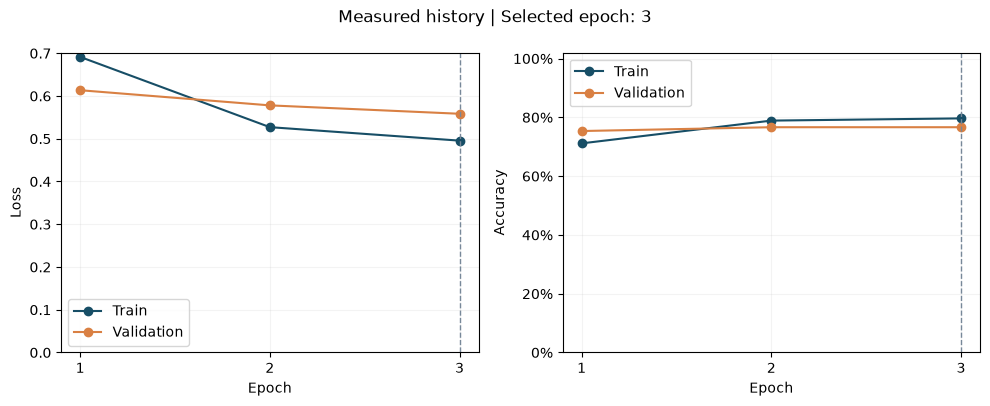

In [8]:
# نرسم القياسات المسجلة فعلًا، مع تحديد مصدرها.
print("Run source:", run_source)
plot_history(history, best_epoch, output="docs/assets/learning_curves.png")

## 9. Independent Test Set Evaluation & Per-Class Sensitivity
Evaluates the fine-tuned model against 624 independent test radiographs to compute multiclass recall.

Test accuracy: 78.8%; Macro recall: 78.1%
BACTERIAL recall: 93.8%
NORMAL recall: 66.2%
VIRAL recall: 74.3%
Rows = true labels; columns = predictions


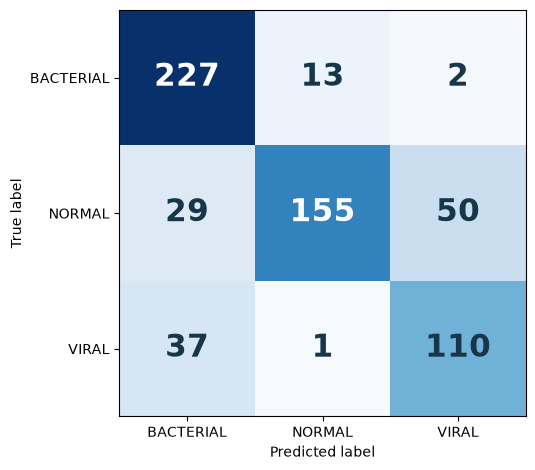

In [9]:
model.eval()
true_labels, predicted_labels = [], []
with torch.inference_mode():
    for x, y in test_loader:
        logits = model(x.to(device))
        true_labels.extend(y.tolist())
        predicted_labels.extend(logits.argmax(dim=1).cpu().tolist())

class_ids = list(range(len(class_names)))
test_accuracy = accuracy_score(true_labels, predicted_labels)
# Track sensitivity / recall independently for each clinical class.
recall_average = None
per_class_recall = recall_score(true_labels, predicted_labels,
                                labels=class_ids, average=recall_average, zero_division=0)
assert np.shape(per_class_recall) == (len(class_names),), "Return one recall per class."
macro_recall = float(np.mean(per_class_recall))
cm = confusion_matrix(true_labels, predicted_labels, labels=class_ids)
print(f"Test accuracy: {test_accuracy:.1%}; Macro recall: {macro_recall:.1%}")
for name, recall in zip(class_names, per_class_recall):
    print(f"{name} recall: {recall:.1%}")
print("Rows = true labels; columns = predictions")
plot_confusion(cm, class_names, output="docs/assets/confusion_matrix.png")


## 10. Model Checkpointing & Artifact Serialization
Serializes state dictionary, class labels, and normalization moments for downstream deployment.

In [10]:
# نحفظ مصدر النموذج المدرب، مع Weights وإعدادات المعالجة.
assert run_source in {"trained_here", "loaded_3class"}, "Model must be trained or loaded before checkpointing."
checkpoint = {
    "state_dict": {name: value.detach().cpu() for name, value in model.state_dict().items()},
    "class_names": class_names,
    "image_size": IMAGE_SIZE,
    "mean": MEAN,
    "std": STD,
    "architecture": "mobilenet_v2",
    "best_epoch": best_epoch,
    "history": history,
    "run_source": run_source,
}
Path("artifacts").mkdir(exist_ok=True)
torch.save(checkpoint, "artifacts/pneumonia_3class.pt")

# نفتح الملف في نموذج جديد للتأكد أن الحفظ قابل للاستخدام.
saved = torch.load("artifacts/pneumonia_3class.pt", map_location="cpu", weights_only=True)
deployed_model = models.mobilenet_v2(weights=None)
deployed_model.classifier[-1] = nn.Linear(deployed_model.last_channel, len(saved["class_names"]))
deployed_model.load_state_dict(saved["state_dict"])
deployed_model = deployed_model.to(device).eval()
print("Saved and reloaded: artifacts/pneumonia_3class.pt")

Saved and reloaded: artifacts/pneumonia_3class.pt


## 11. Single-Image Inference Engine
Implements preprocessing and uncalibrated Softmax probability extraction.

In [11]:
# نعيد المعالجة نفسها التي حفظناها مع Checkpoint.
prediction_transform = transforms.Compose([
    transforms.Resize((saved["image_size"], saved["image_size"])),
    transforms.ToTensor(),
    transforms.Normalize(saved["mean"], saved["std"]),
])

def predict(image_path):
    image = Image.open(image_path).convert("RGB")
    # نضيف بُعد Batch: صورة واحدة تصبح [1, 3, 224, 224].
    x = prediction_transform(image).unsqueeze(0).to(device)
    with torch.inference_mode():
        # Softmax للعرض بعد Prediction، وليست قبل Training Loss.
        scores = deployed_model(x).softmax(dim=1)[0].cpu()
    index = int(scores.argmax().item())
    # Dictionary: اسم Class، ثم Score لكل Class.
    return {"label": saved["class_names"][index],
            "scores": {name: float(scores[i]) for i, name in enumerate(saved["class_names"])}}

## 12. Qualitative Diagnostic Verification
Executes inference across representative examples for each diagnostic class.

Dataset label: BACTERIAL Prediction: BACTERIAL


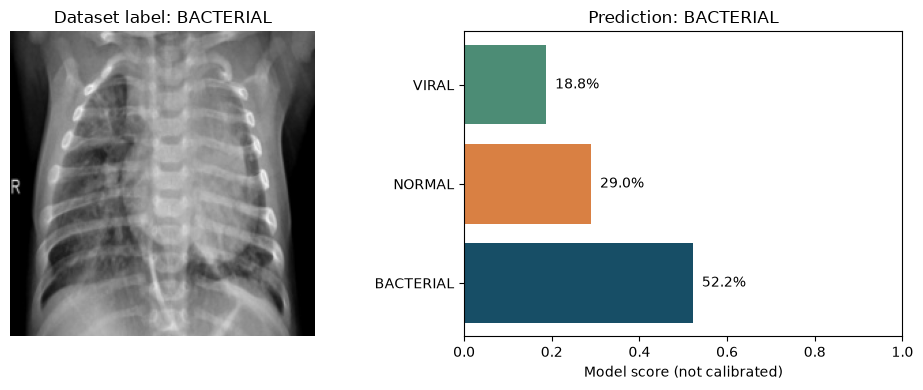

Dataset label: NORMAL Prediction: NORMAL


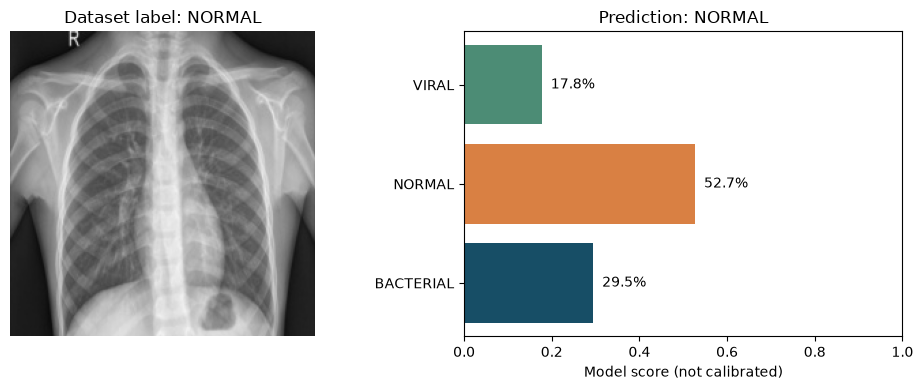

Dataset label: VIRAL Prediction: BACTERIAL


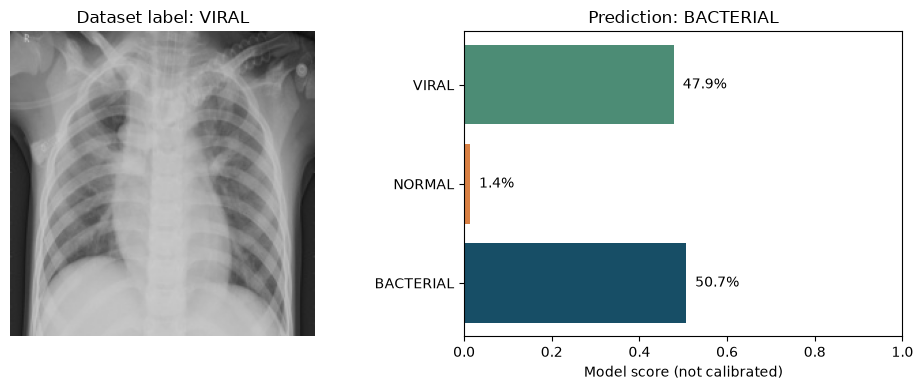

In [12]:
# Evaluate single test examples for each clinical category.
for label, name in enumerate(class_names):
    image_path, known_label = next(sample for sample in test_data.samples if sample[1] == label)
    result = predict(image_path)
    print("Dataset label:", name, "Prediction:", result["label"])
    show_prediction(image_path, result, true_label=name,
                    output=f"homework_outputs/prediction_{name}.png")


## 13. Explainable AI: Grad-CAM Pulmonary Saliency Maps
Computes Gradient-weighted Class Activation Mapping from the final feature extractor to localize predictive anatomic regions.

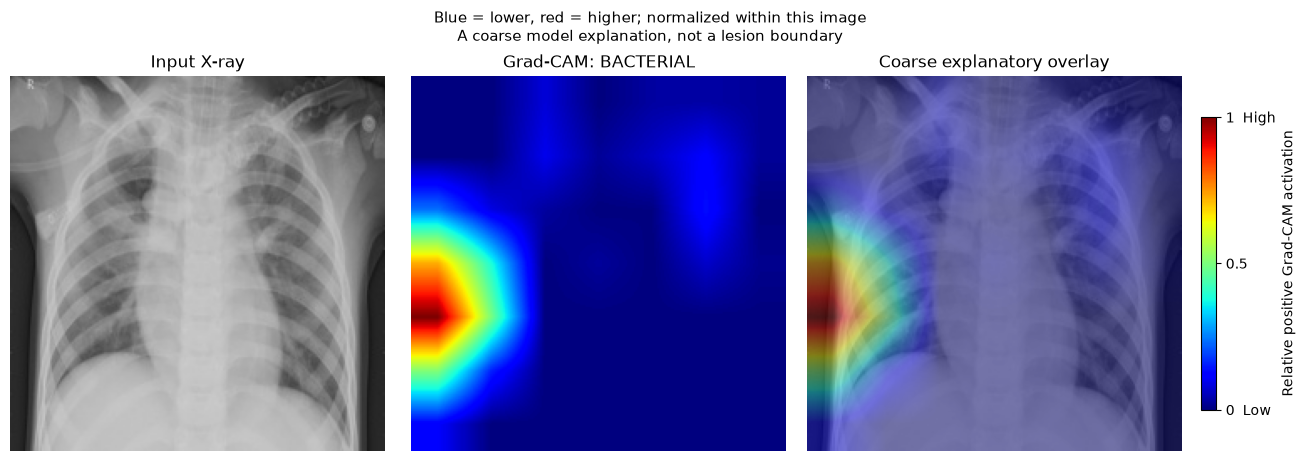

Explained class: BACTERIAL


In [13]:
# نفس الصورة ونفس النموذج؛ نحسب التفسير بدون تحديث Weights.
cam_info = show_gradcam(deployed_model, image_path, prediction_transform,
                        saved["class_names"], device, output="docs/assets/gradcam.png")
print("Explained class:", cam_info["target_class"])